In [2]:
import zipfile
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Zip extract
try:
    with zipfile.ZipFile('project 2-20261010T170020Z-1-001.zip', 'r') as zip_ref:
        zip_ref.extractall('.')
    print("✅ Zip extracted")
except:
    print("Already extracted or zip not found")
    
print(os.listdir('.'))

✅ Zip extracted
['Untitled10.ipynb', 'firstnotebook (copy).ipynb', 'firstnotebook.ipynb', 'fourthnotebook.ipynb', 'project 2', 'project 2-20261010T170020Z-1-001.zip', 'web.designing.docx']


In [3]:
# project 2 folder ullukulla enna irukku nu paapom
print(os.listdir('project 2'))

# Innonum ulla po
import pathlib
for root, dirs, files in os.walk('.'):
    for f in files:
        if f.endswith('.csv'):
            print(os.path.join(root, f))

['ecomm_01_10_2026.ipynb', 'ecommerce_sales_professional_unclean.csv']
./project 2/ecommerce_sales_professional_unclean.csv


In [4]:
# MAIN DATA CLEANING CODE
df = pd.read_csv('./project 2/ecommerce_sales_professional_unclean.csv')

print("BEFORE Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
df.head()

BEFORE Shape: (1020, 24)

Columns: ['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Gender', 'Age', 'City', 'State', 'Region', 'Product_ID', 'Product_Name', 'Category', 'Brand', 'Quantity', 'Unit_Price', 'Discount_%', 'Cost_Price', 'Total_Sales', 'Profit', 'Payment_Mode', 'Order_Status', 'Shipping_Cost', 'Delivery_Days', 'Rating']

Missing values:
 Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name    31
Gender            0
Age               0
City              0
State             0
Region            0
Product_ID        0
Product_Name      0
Category         25
Brand             0
Quantity          0
Unit_Price        0
Discount_%        0
Cost_Price        0
Total_Sales       0
Profit            0
Payment_Mode      0
Order_Status      0
Shipping_Cost     0
Delivery_Days     0
Rating            0
dtype: int64

Duplicates: 20


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_ID,...,Unit_Price,Discount_%,Cost_Price,Total_Sales,Profit,Payment_Mode,Order_Status,Shipping_Cost,Delivery_Days,Rating
0,ORD100001,14-07-2025,C1274,Customer_288,Female,39,Chennai,Tamil Nadu,North,P1436,...,999,0,800.75,6993.0,1387.75,Credit Card,Delivered,59,6,5
1,ORD100002,05-02-2025,C1003,Customer_162,Female,24,Erode,Tamil Nadu,West,P1463,...,2499,150,2033.16,2499.0,465.84,UPI,Delivered,233,3,1
2,ORD100003,25-06-2025,C1267,Customer_248,Male,56,Trichy,Tamil Nadu,Central,P1327,...,999,15,800.55,6793.2,388.80,Net Banking,Delivered,196,1,4
3,ORD100004,27-11-2025,C1092,NaN,Female,60,Tirunelveli,Tamil Nadu,South,P1134,...,9999,15,6622.90,67993.2,15010.00,Debit Card,Delivered,56,9,4
4,ORD100005,07-01-2025,C1180,Customer_118,Female,52,Coimbatore,Tamil Nadu,West,P1256,...,199,5,144.45,1134.3,267.60,Debit Card,Returned,226,4,5


In [7]:
print("BEFORE:", df.shape)
df = df.drop_duplicates()

# Missing fill
df['Customer_Name'] = df['Customer_Name'].fillna(df['Customer_ID'])

cols = ['Age','Unit_Price','Discount_%','Cost_Price','Total_Sales','Rating']
for c in cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')
        df[c] = df[c].fillna(df[c].median())

# Gender fix
df['Gender'] = df['Gender'].astype(str).str.title()
df['Gender'] = df['Gender'].fillna('Unknown')

# Date fix
df['Order_Date'] = pd.to_datetime(df['Order_Date'], dayfirst=True, errors='coerce')

# Discount fix
df.loc[df['Discount_%'] > 100, 'Discount_%'] = df.loc[df['Discount_%'] > 100, 'Discount_%'] / 10

# Positive
df['Unit_Price'] = df['Unit_Price'].abs()
df['Total_Sales'] = df['Total_Sales'].abs()

print("AFTER:", df.shape)
print("Missing:", df.isnull().sum().sum())
df.head()

BEFORE: (1020, 24)
AFTER: (1000, 24)
Missing: 45


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_ID,...,Unit_Price,Discount_%,Cost_Price,Total_Sales,Profit,Payment_Mode,Order_Status,Shipping_Cost,Delivery_Days,Rating
0,ORD100001,2025-07-14,C1274,Customer_288,Female,39,Chennai,Tamil Nadu,North,P1436,...,999,0,800.75,6993.0,1387.75,Credit Card,Delivered,59,6,5
1,ORD100002,2025-02-05,C1003,Customer_162,Female,24,Erode,Tamil Nadu,West,P1463,...,2499,15,2033.16,2499.0,465.84,UPI,Delivered,233,3,1
2,ORD100003,2025-06-25,C1267,Customer_248,Male,56,Trichy,Tamil Nadu,Central,P1327,...,999,15,800.55,6793.2,388.80,Net Banking,Delivered,196,1,4
3,ORD100004,2025-11-27,C1092,C1092,Female,60,Tirunelveli,Tamil Nadu,South,P1134,...,9999,15,6622.90,67993.2,15010.00,Debit Card,Delivered,56,9,4
4,ORD100005,2025-01-07,C1180,Customer_118,Female,52,Coimbatore,Tamil Nadu,West,P1256,...,199,5,144.45,1134.3,267.60,Debit Card,Returned,226,4,5


In [8]:
# Remaining 45 missing clean pannu
print(df.isnull().sum()[df.isnull().sum()>0])

# Fill remaining
df['City'] = df['City'].fillna('Unknown')
df['State'] = df['State'].fillna('Tamil Nadu')
df['Region'] = df['Region'].fillna('South')
df['Product_ID'] = df['Product_ID'].fillna('P0000')
df['Customer_Name'] = df['Customer_Name'].fillna('Unknown')

# Any other NaN -> 0
df = df.fillna(0)

print("\nFinal Missing:", df.isnull().sum().sum(), " - 0 varanum")
print("Final Shape:", df.shape)

Order_Date    20
Category      25
dtype: int64

Final Missing: 0  - 0 varanum
Final Shape: (1000, 24)


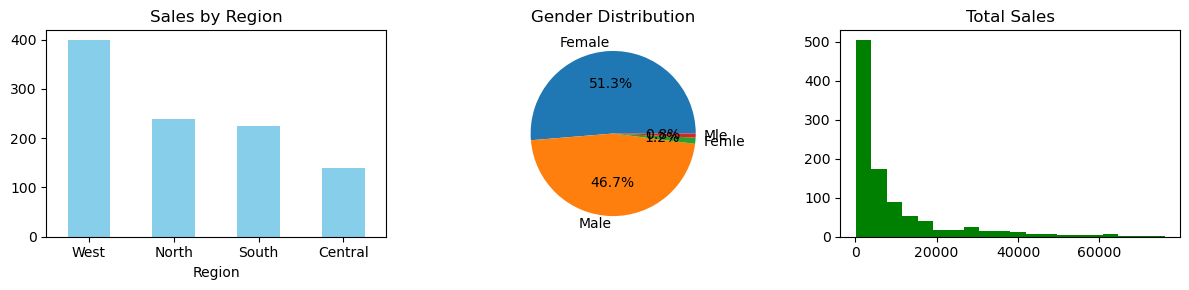

✅ DONE! File saved as CLEAN_FINAL_PROJECT2.csv


In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,3))

plt.subplot(1,3,1)
df['Region'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Sales by Region')
plt.xticks(rotation=0)

plt.subplot(1,3,2)
df['Gender'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Gender Distribution')

plt.subplot(1,3,3)
plt.hist(df['Total_Sales'], bins=20, color='green')
plt.title('Total Sales')

plt.tight_layout()
plt.show()

# Final save
df.to_csv('CLEAN_FINAL_PROJECT2.csv', index=False)
print("✅ DONE! File saved as CLEAN_FINAL_PROJECT2.csv")